# Titanic Survival Prediction — End-to-End Machine Learning Project

This project builds a supervised binary classification pipeline to predict passenger survival on the Titanic using historical passenger data. It covers data cleaning, feature engineering, exploratory data analysis, model comparison, and inference on new passenger records.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

sns.set_theme(style="whitegrid")

In [3]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(DATA_URL)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())

print("\nMissing Values per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTarget Distribution (Survived):")
print(df["Survived"].value_counts(normalize=True).round(4))

Dataset Shape: 891 rows, 12 columns



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Missing Values per Column:
Age         177
Cabin       687
Embarked      2
dtype: int64

Target Distribution (Survived):
Survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


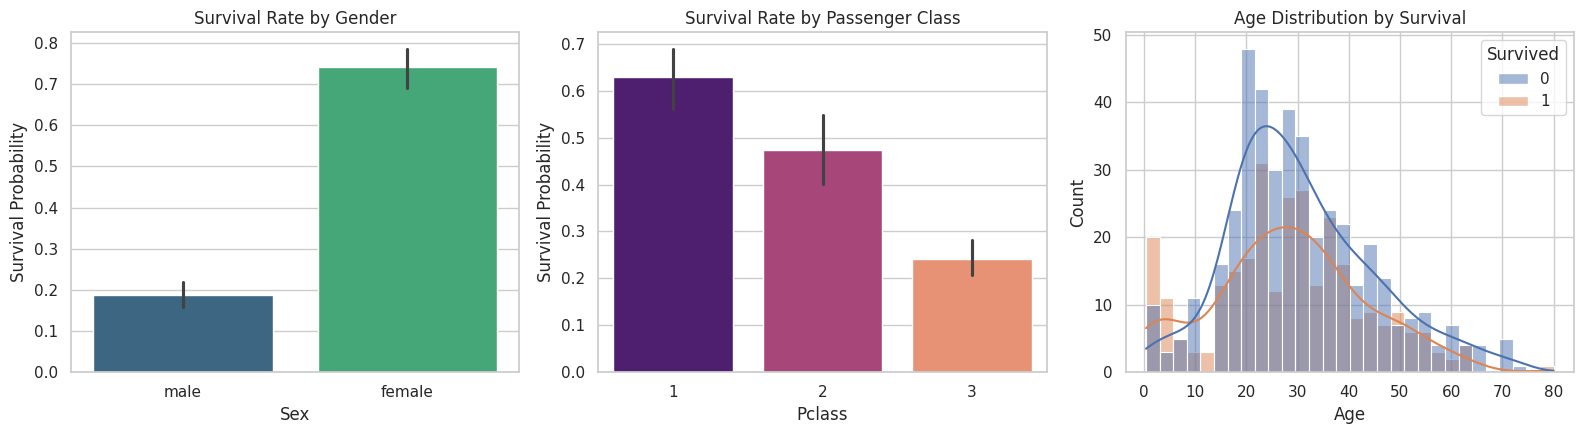

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0], palette="viridis")
axes[0].set_title("Survival Rate by Gender")
axes[0].set_ylabel("Survival Probability")

sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1], palette="magma")
axes[1].set_title("Survival Rate by Passenger Class")
axes[1].set_ylabel("Survival Probability")

sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[2])
axes[2].set_title("Age Distribution by Survival")

plt.tight_layout()
plt.show()

In [5]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()

    # Extract Title from Name (e.g., Mr., Mrs., Miss., Master.)
    data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    rare_titles = data["Title"].value_counts()[data["Title"].value_counts() < 10].index
    data["Title"] = data["Title"].replace(rare_titles, "Rare")

    # Family size & solo travel indicator
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

    # Drop high-cardinality / identifier columns not needed directly
    drop_cols = ["PassengerId", "Name", "Ticket", "Cabin"]
    return data.drop(columns=drop_cols)

df_clean = engineer_features(df)

X = df_clean.drop(columns=["Survived"])
y = df_clean["Survived"]

numeric_features = ["Age", "Fare", "SibSp", "Parch", "FamilySize", "IsAlone"]
categorical_features = ["Sex", "Embarked", "Pclass", "Title"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")

Training samples: 712 | Test samples: 179


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=7, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42)
}

results = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])

    cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "CV Mean Accuracy": round(cv_scores.mean(), 4),
        "CV Std": round(cv_scores.std(), 4),
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values(by="Test ROC-AUC", ascending=False)
display(results_df)

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_pipelines[best_model_name]
print(f"\nBest Model Selected: {best_model_name}")

,Model,CV Mean Accuracy,CV Std,Test Accuracy,Test ROC-AUC
0,Logistic Regression,0.8189,0.0222,0.8492,0.8779
1,Random Forest,0.8133,0.0214,0.8045,0.8567
2,Gradient Boosting,0.8175,0.0271,0.8212,0.8536



Best Model Selected: Logistic Regression


Classification Report (Logistic Regression):

              precision    recall  f1-score   support

Not Survived       0.86      0.90      0.88       110
    Survived       0.83      0.77      0.80        69

    accuracy                           0.85       179
   macro avg       0.84      0.83      0.84       179
weighted avg       0.85      0.85      0.85       179



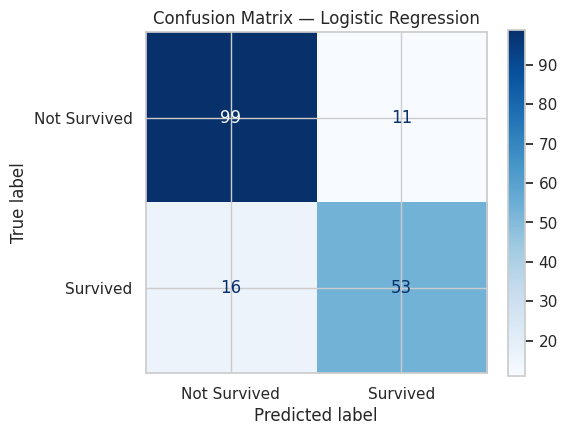

In [7]:
y_pred_best = best_model.predict(X_test)

print(f"Classification Report ({best_model_name}):\n")
print(classification_report(y_test, y_pred_best, target_names=["Not Survived", "Survived"]))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues",
    ax=ax
)
ax.set_title(f"Confusion Matrix — {best_model_name}")
plt.show()

In [8]:
def predict_passenger_survival(passenger_info: dict, model_pipeline: Pipeline) -> dict:
    raw_df = pd.DataFrame([passenger_info])
    engineered_df = engineer_features(raw_df)
    pred = int(model_pipeline.predict(engineered_df)[0])
    prob = float(model_pipeline.predict_proba(engineered_df)[0][1])

    return {
        "Prediction": "Survived" if pred == 1 else "Did Not Survive",
        "Survival Probability": f"{prob * 100:.2f}%"
    }

sample_passenger = {
    "PassengerId": 999,
    "Name": "Ali, Mr. Tariq",
    "Pclass": 1,
    "Sex": "male",
    "Age": 28.0,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 75.0,
    "Ticket": "PC 17599",
    "Cabin": "C85",
    "Embarked": "S"
}

print(predict_passenger_survival(sample_passenger, best_model))

{'Prediction': 'Survived', 'Survival Probability': '61.04%'}
